# Pivot-structure × regime — premise tests (trend_pivot)

Structural hypothesis to validate *before* building anything:

- **Uptrend** — higher highs & higher lows; a prior high pivot (old resistance)
  becomes support for the next low → **accumulate** there; trim into new highs.
- **Downtrend** — mirror.
- **Range** — pivots oscillate in a band → **fade both ends**.

Four falsifiable tests on the **29-name LS∩lake** set, under **three regime
definitions** — R1 pivot-structure, R2 price efficiency-ratio, R3 hybrid — each
reported **per-name gross** and **market-excess** (beta-neutral, minus the equal-
weight universe). Crypto is ~one beta factor, so the market-excess column is the
one that matters for a real edge.

> Test 3 uses the *realized* pivots as entry/exit — perfect timing — so it is an
> **upper bound** on what's capturable. If even the upper bound is flat in excess,
> the overlay is dead. If it's positive, Phase 2 designs realistic ex-ante-level
> execution (rest bids at prior-high support).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
REPO_ROOT = Path.cwd()
while not (REPO_ROOT / "src").is_dir() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (13, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold"})

from src.data.query import get
from src.signals.jason import compute_jason_vectorized
from research.jason.pivots import (pivot_importance, significant_pivots, zigzag,
    regime_price, regime_pivots, regime_hybrid, label_regime)
from scripts.ls_bot import UNIVERSE as LS_UNIVERSE, CLARITY
# re-assert inline (ls_bot import forces matplotlib.use("Agg")):
%matplotlib inline

TF, LOOKBACK, NP, MD, Q = "1h", 7, 5, 1, 0.50
ER_WIN, PIV_K = 168, 4          # efficiency-ratio window (7d), pivots looked back for structure
DEFS = ["R1_pivot", "R2_price", "R3_hybrid"]

cands = list(dict.fromkeys(LS_UNIVERSE + CLARITY))
data = {}
for t in cands:
    df = get("perps", "binance", t.lower(), "bars", TF, start="2021-01-01")
    if not df.empty and len(df) >= 8760 and (df.index[-1]-df.index[0]).days/365.25 >= 1.5:
        data[t] = df
UNIVERSE = list(data)
print(f"universe: {len(UNIVERSE)} names")

2026-07-24 15:05:23,860 WARNING  query | no data for perps/binance/ccusdt/bars (stage=auto); returning empty frame


2026-07-24 15:05:23,990 WARNING  query | no data for perps/binance/vvvusdt/bars (stage=auto); returning empty frame


2026-07-24 15:05:23,998 WARNING  query | no data for perps/binance/billusdt/bars (stage=auto); returning empty frame


2026-07-24 15:05:24,000 WARNING  query | no data for perps/binance/magmausdt/bars (stage=auto); returning empty frame


2026-07-24 15:05:24,010 WARNING  query | no data for perps/binance/aerousdt/bars (stage=auto); returning empty frame


...

2026-07-24 15:05:24,025 WARNING  query | no data for perps/binance/nvdausdt/bars (stage=auto); returning empty frame


2026-07-24 15:05:24,026 WARNING  query | no data for perps/binance/aaplusdt/bars (stage=auto); returning empty frame


2026-07-24 15:05:24,027 WARNING  query | no data for perps/binance/tslausdt/bars (stage=auto); returning empty frame


2026-07-24 15:05:24,028 WARNING  query | no data for perps/binance/skhynixusdt/bars (stage=auto); returning empty frame


universe: 29 names


## Extract pivots + regimes per name, build the market index

Per name: significant-pivot zig-zag, the three regime label series, and bar
log-returns. The market index is the equal-weight mean bar log-return across the
universe (for the beta-neutral market-excess).

In [2]:
seqs, labels, logret = {}, {}, {}
for t, ohlc in data.items():
    close = ohlc["close"]
    piv = pivot_importance(ohlc, TF, LOOKBACK, NP, MD)
    ev, _, _ = significant_pivots(piv, ohlc, Q)
    seq = zigzag(ev)
    seqs[t] = seq
    r = {"R1_pivot": regime_pivots(seq, ohlc.index, PIV_K),
         "R2_price": regime_price(close, ER_WIN),
         "R3_hybrid": regime_hybrid(close, seq, ohlc.index, ER_WIN, PIV_K)}
    labels[t] = {d: label_regime(r[d]) for d in DEFS}
    logret[t] = np.log(close).diff()

mkt_logret = pd.concat(logret, axis=1).mean(axis=1)   # equal-weight market bar return
mkt_level = mkt_logret.cumsum()                        # market log-level (for windowed excess)
print(f"market index bars: {mkt_level.notna().sum():,}")

market index bars: 48,725


## Test 1 — does structure exist? (HH / HL rate by regime)

For consecutive same-type pivots, is the new one higher (HH for highs, HL for
lows)? Tagged by the regime at the newer pivot. Uptrend should show HH & HL well
above the 0.5 chance line; downtrend well below; range near 0.5.

In [3]:
rows = []
for t in UNIVERSE:
    seq = seqs[t]
    highs = [(e[0], e[2], e[4]) for e in seq if e[1] == "H"]
    lows = [(e[0], e[2], e[4]) for e in seq if e[1] == "L"]
    for series, typ in [(highs, "HH"), (lows, "HL")]:
        for (b0, p0, _), (b1, p1, ts1) in zip(series, series[1:]):
            rec = {"typ": typ, "rising": int(p1 > p0)}
            for d in DEFS:
                rec[d] = labels[t][d].get(ts1, "range")
            rows.append(rec)
struct = pd.DataFrame(rows)

t1 = {}
for d in DEFS:
    g = struct.groupby([d, "typ"])["rising"].mean().unstack()
    t1[d] = g
    print(f"\n[{d}]  P(rising pivot) by regime  (chance=0.50)")
    print(g.reindex(["up", "range", "down"]).round(3).to_string())


[R1_pivot]  P(rising pivot) by regime  (chance=0.50)
typ          HH     HL
R1_pivot              
up        0.476  0.534
range     0.076  0.086
down      0.436  0.520

[R2_price]  P(rising pivot) by regime  (chance=0.50)
typ          HH     HL
R2_price              
up        0.624  0.729
range     0.102  0.133
down      0.260  0.388

[R3_hybrid]  P(rising pivot) by regime  (chance=0.50)
typ           HH     HL
R3_hybrid              
up         0.506  0.564
range      0.117  0.132
down       0.404  0.487


## Test 2 — role-reversal support (uptrend)

For each low pivot, compare it to the **prior high pivot two swings back**
(`H_{i-1}` — the old resistance): `low / prior_high − 1`. If old highs become
support, uptrend lows sit **at or just above** it (ratio ≳ 0, hold-rate high).
Down/range shown for contrast.


[R1_pivot] role-reversal support
          median(low/priorHigh-1)  hold-rate(low>=priorHigh)
R1_pivot                                                    
up                        -0.0551                      0.103
range                      0.0000                      0.850
down                      -0.0685                      0.058

[R2_price] role-reversal support
          median(low/priorHigh-1)  hold-rate(low>=priorHigh)
R2_price                                                    
up                        -0.0343                      0.192
range                      0.0000                      0.764
down                      -0.0840                      0.015

[R3_hybrid] role-reversal support
           median(low/priorHigh-1)  hold-rate(low>=priorHigh)
R3_hybrid                                                    
up                         -0.0519                      0.117
range                       0.0000                      0.772
down                       -0.0754     

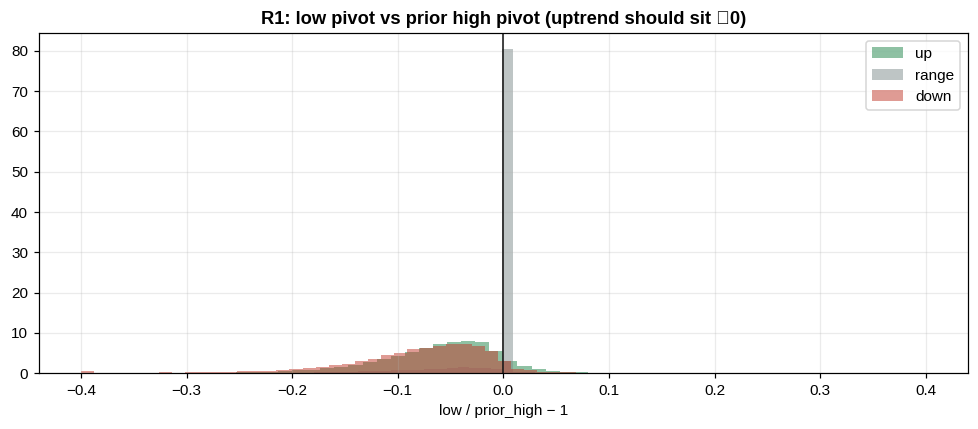

In [4]:
rows = []
for t in UNIVERSE:
    seq = seqs[t]
    for j in range(3, len(seq)):
        if seq[j][1] != "L" or seq[j-3][1] != "H":
            continue
        low_px, prior_high = seq[j][2], seq[j-3][2]
        ts = seq[j][4]
        rec = {"ratio": low_px / prior_high - 1.0, "held": int(low_px >= prior_high)}
        for d in DEFS:
            rec[d] = labels[t][d].get(ts, "range")
        rows.append(rec)
rr = pd.DataFrame(rows)

for d in DEFS:
    tab = rr.groupby(d)["ratio"].median().reindex(["up", "range", "down"])
    hold = rr.groupby(d)["held"].mean().reindex(["up", "range", "down"])
    out = pd.DataFrame({"median(low/priorHigh-1)": tab.round(4), "hold-rate(low>=priorHigh)": hold.round(3)})
    print(f"\n[{d}] role-reversal support")
    print(out.to_string())

fig, ax = plt.subplots(figsize=(9, 4))
for g, c in [("up", "#1e8449"), ("range", "#7f8c8d"), ("down", "#c0392b")]:
    s = rr[rr["R1_pivot"] == g]["ratio"].clip(-0.4, 0.4)
    ax.hist(s, bins=60, alpha=0.5, density=True, color=c, label=g)
ax.axvline(0, color="#111", lw=1); ax.set_title("R1: low pivot vs prior high pivot (uptrend should sit ≳0)")
ax.set_xlabel("low / prior_high − 1"); ax.legend(); plt.tight_layout()
plt.savefig(REPO_ROOT / "pivot_regime_rolereversal.png", bbox_inches="tight"); plt.show()

## Test 3 — payoff by regime (idealized pivot capture, gross & market-excess)

Each zig-zag leg: **up-leg** = long from low→high, **down-leg** = short from
high→low. Return tagged by regime at entry. `gross` = the directional leg return;
`excess` = beta-neutral (leg minus the market's move over the same window,
sign-adjusted). **This is perfect-timing → an upper bound.**

Hypothesis: up-legs positive-excess in **uptrends**, down-legs positive-excess in
**downtrends**, and in **range** both legs positive-excess (fade both ends). If
`excess` collapses to ~0, the swing is just beta and there's nothing to capture.

In [5]:
def mkt_between(a_ts, b_ts):
    la, lb = mkt_level.get(a_ts, np.nan), mkt_level.get(b_ts, np.nan)
    return lb - la

rows = []
for t in UNIVERSE:
    seq = seqs[t]
    for a, b in zip(seq, seq[1:]):
        kind = "up" if a[1] == "L" else "down"
        sign = 1.0 if kind == "up" else -1.0
        name_leg = np.log(b[2] / a[2])
        m = mkt_between(a[4], b[4])
        rec = {"kind": kind, "gross": sign * name_leg, "excess": sign * (name_leg - m),
               "dur_d": (b[0] - a[0]) / 24.0}
        for d in DEFS:
            rec[d] = labels[t][d].get(a[4], "range")
        rows.append(rec)
legs = pd.DataFrame(rows).dropna(subset=["excess"])

def summary(dfk, d):
    g = dfk.groupby(d).agg(n=("excess", "size"),
                           gross_mean=("gross", "mean"), excess_mean=("excess", "mean"),
                           excess_hit=("excess", lambda s: (s > 0).mean()))
    return g.reindex(["up", "range", "down"]).round(4)

for kind in ["up", "down"]:
    print(f"\n===== {kind.upper()}-LEG  ({'long L→H' if kind=='up' else 'short H→L'}) =====")
    for d in DEFS:
        print(f"\n[{d}]")
        print(summary(legs[legs.kind == kind], d).to_string())


===== UP-LEG  (long L→H) =====

[R1_pivot]
              n  gross_mean  excess_mean  excess_hit
R1_pivot                                            
up        13919      0.0793       0.0494      0.9461
range     40369      0.0122       0.0070      0.5579
down      14581      0.0791       0.0434      0.9368

[R2_price]
              n  gross_mean  excess_mean  excess_hit
R2_price                                            
up         9612      0.0863       0.0571      0.9509
range     45212      0.0178       0.0102      0.5980
down      14045      0.0794       0.0425      0.9381

[R3_hybrid]
               n  gross_mean  excess_mean  excess_hit
R3_hybrid                                            
up         11738      0.0812       0.0514      0.9477
range      44896      0.0181       0.0104      0.5960
down       12235      0.0805       0.0435      0.9376

===== DOWN-LEG  (short H→L) =====

[R1_pivot]
              n  gross_mean  excess_mean  excess_hit
R1_pivot                       

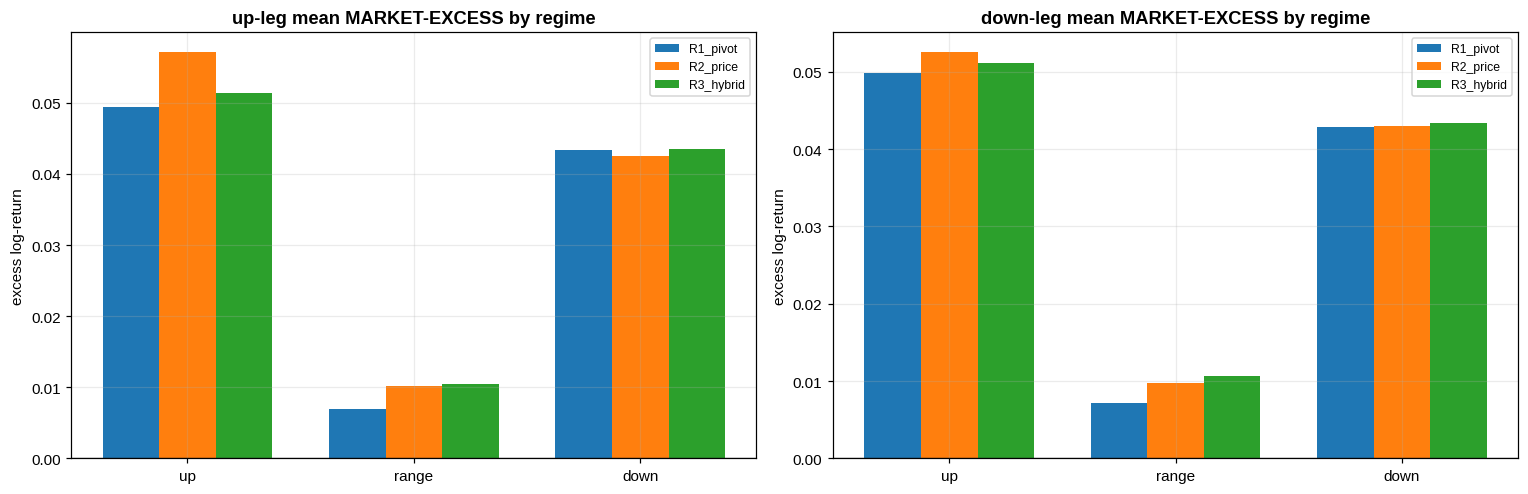

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
xr = ["up", "range", "down"]
w = 0.25
for ax, kind in zip(axes, ["up", "down"]):
    for i, d in enumerate(DEFS):
        s = summary(legs[legs.kind == kind], d)["excess_mean"].reindex(xr)
        ax.bar(np.arange(len(xr)) + (i-1)*w, s.values, w, label=d)
    ax.axhline(0, color="#111", lw=0.8); ax.set_xticks(range(len(xr))); ax.set_xticklabels(xr)
    ax.set_title(f"{kind}-leg mean MARKET-EXCESS by regime"); ax.set_ylabel("excess log-return")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(REPO_ROOT / "pivot_regime_payoff.png", bbox_inches="tight"); plt.show()

## Test 4 — which regime detector separates best?

The overlay wants the regime label to make the aligned leg **positive-excess** and
the counter leg **negative/zero-excess**. Score each detector by the *spread* it
creates: (up-leg excess in uptrend − up-leg excess in downtrend) + (down-leg
excess in downtrend − down-leg excess in uptrend). Bigger = the regime label
actually sorts the payoff.

In [7]:
sep = {}
for d in DEFS:
    up = summary(legs[legs.kind == "up"], d)["excess_mean"]
    dn = summary(legs[legs.kind == "down"], d)["excess_mean"]
    sep[d] = {
        "up-leg (up−down regime)": round(up["up"] - up["down"], 4),
        "down-leg (down−up regime)": round(dn["down"] - dn["up"], 4),
        "range up-leg excess": round(up["range"], 4),
        "range down-leg excess": round(dn["range"], 4),
    }
sep_df = pd.DataFrame(sep).T
sep_df["separation"] = sep_df["up-leg (up−down regime)"] + sep_df["down-leg (down−up regime)"]
print("Regime-detector separation (bigger = label sorts the payoff better):")
print(sep_df.round(4).to_string())

Regime-detector separation (bigger = label sorts the payoff better):
           up-leg (up−down regime)  down-leg (down−up regime)  range up-leg excess  range down-leg excess  separation
R1_pivot                    0.0060                    -0.0069               0.0070                 0.0071     -0.0009
R2_price                    0.0146                    -0.0095               0.0102                 0.0098      0.0051
R3_hybrid                   0.0079                    -0.0078               0.0104                 0.0107      0.0001


## Visual inspection — BTC (individual pivots + regime + ±kσ levels)

The eyeball check, inline. Price with the **individual significant pivots**
(▲ low / ▼ high — real swing extrema, not the composite), the regime as background
shading (green=up, red=down, white=range, R2), and the JASON **±2 / 2.5σ levels**
(dotted). Two contrasting windows so you can judge: do pivots ratchet in trends,
and do pullback lows hold at prior highs (accumulation) or slice through?

Computing JASON for BTCUSDT:   0%|          | 0/48558 [00:00<?, ?it/s]

Computing JASON for BTCUSDT:   0%|          | 1/48558 [00:04<57:28:58,  4.26s/it]

Computing JASON for BTCUSDT:   9%|▉         | 4465/48558 [00:04<00:30, 1448.06it/s]

Computing JASON for BTCUSDT:  18%|█▊        | 8958/48558 [00:04<00:11, 3373.49it/s]

Computing JASON for BTCUSDT:  28%|██▊       | 13431/48558 [00:04<00:06, 5833.98it/s]

...

Computing JASON for BTCUSDT:  55%|█████▍    | 26579/48558 [00:04<00:01, 16220.71it/s]

Computing JASON for BTCUSDT:  64%|██████▍   | 30962/48558 [00:04<00:00, 20423.71it/s]

Computing JASON for BTCUSDT:  73%|███████▎  | 35462/48558 [00:05<00:00, 24813.49it/s]

Computing JASON for BTCUSDT:  82%|████████▏ | 39922/48558 [00:05<00:00, 28835.91it/s]

Computing JASON for BTCUSDT:  91%|█████████▏| 44356/48558 [00:05<00:00, 32325.13it/s]

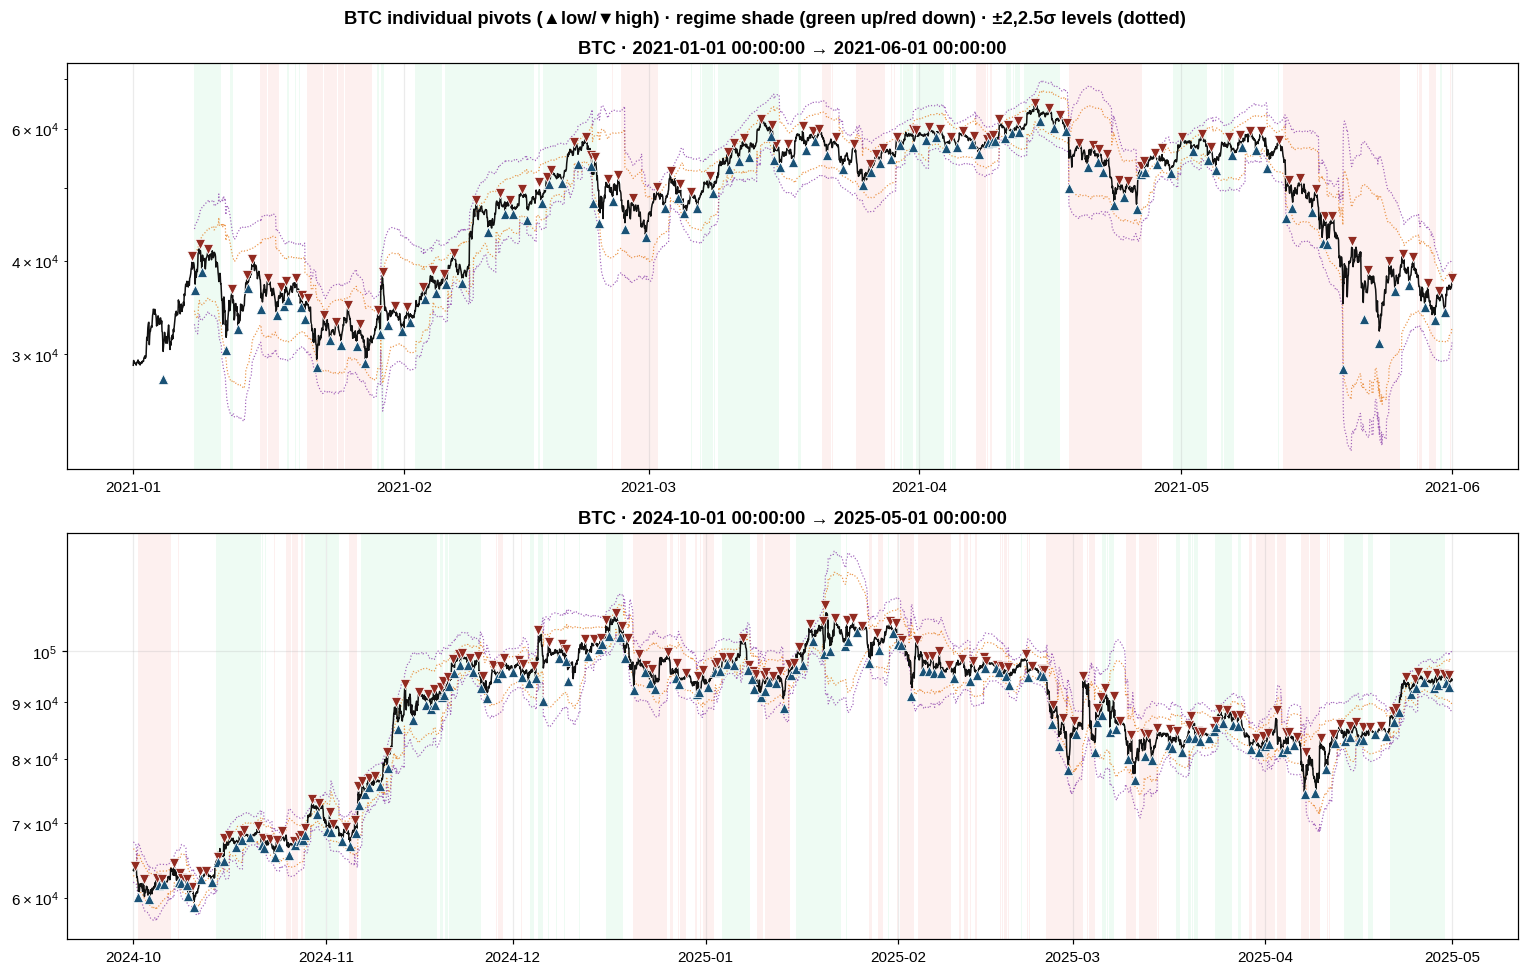

In [8]:
bt = data["BTCUSDT"]
bclose = bt["close"]
bseq = seqs["BTCUSDT"]
blab = labels["BTCUSDT"]["R2_price"]
bfeat = compute_jason_vectorized(bt.copy(), "BTCUSDT", TF, lookback=LOOKBACK, n_pivots=NP, min_days=MD)
bhp, blp = bfeat["high_pivot"], bfeat["low_pivot"]
lvl_dn = {k: bhp * np.exp(-k * (-0.5 * np.log(bfeat["json2_dn"] / bhp))) for k in (2.0, 2.5)}
lvl_up = {k: blp * np.exp(k * (0.5 * np.log(bfeat["json2_up"] / blp))) for k in (2.0, 2.5)}

def _panel(ax, start, end):
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    m = (bclose.index >= start) & (bclose.index <= end)
    ts = bclose.index[m]
    codes = blab[m].map({"up": 1, "range": 0, "down": -1}).to_numpy()
    b = 0
    for i in range(1, len(codes) + 1):
        if i == len(codes) or codes[i] != codes[b]:
            col = {1: "#2ecc71", -1: "#e74c3c", 0: None}[codes[b]]
            if col:
                ax.axvspan(ts[b], ts[i - 1], color=col, alpha=0.08, lw=0)
            b = i
    ax.plot(ts, bclose[m].values, color="#111", lw=1.0, zorder=3)
    for k, c in [(2.0, "#e67e22"), (2.5, "#8e44ad")]:
        fm = (lvl_up[k].index >= start) & (lvl_up[k].index <= end)
        ax.plot(lvl_up[k].index[fm], lvl_up[k][fm].values, color=c, lw=0.8, ls=":", alpha=0.8)
        ax.plot(lvl_dn[k].index[fm], lvl_dn[k][fm].values, color=c, lw=0.8, ls=":", alpha=0.8)
    win = [e for e in bseq if start <= e[4] <= end]
    ax.scatter([e[4] for e in win if e[1] == "H"], [e[2] for e in win if e[1] == "H"],
               marker="v", s=45, color="#922b21", edgecolor="white", linewidth=0.5, zorder=4)
    ax.scatter([e[4] for e in win if e[1] == "L"], [e[2] for e in win if e[1] == "L"],
               marker="^", s=45, color="#1a5276", edgecolor="white", linewidth=0.5, zorder=4)
    ax.set_yscale("log"); ax.set_title(f"BTC · {start} → {end}")

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
_panel(axes[0], "2021-01-01", "2021-06-01")   # 2021 bull
_panel(axes[1], "2024-10-01", "2025-05-01")   # recent
fig.suptitle("BTC individual pivots (▲low/▼high) · regime shade (green up/red down) · ±2,2.5σ levels (dotted)",
             fontweight="bold")
plt.tight_layout(); plt.savefig(REPO_ROOT / "pivot_regime_btc_visual.png", bbox_inches="tight"); plt.show()

## Read & next

Judge on **market-excess**, not gross (gross is mostly beta). The go/no-go:

- **Test 1/2 positive** (structure + role-reversal hold) → the pivots carry real
  regime-dependent structure worth trading around.
- **Test 3 excess > 0** in the aligned cells (and range symmetric) → there is a
  capturable swing beyond beta, even if this is the perfect-timing upper bound.
- **Test 4** picks the regime detector.

If the excess collapses to ~0 everywhere, the swing is beta and the overlay is a
null (documented, clean). If it survives, Phase 2 builds the realistic version:
rest accumulation bids at the ex-ante-known prior-high support, size by regime
confidence, beta-neutral book, thesis-based invalidation (structure break) — and
we re-test with real execution + costs.